In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Let's take a look at the Pigot data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("./diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
length(cpal10)

47

Import the birds. This is one of many.

In [7]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/UK_BBS_Bird_Data.csv", DataFrame)
gd = groupby(read_data, :Site)

Row,Site,Binomial,Body_Mass,N,WaterBird
,Int64,Int64,Float64,Float64,Int64
1,1,1,3302.41,32.0,1
2,1,2,1486.0,1.0,1
3,1,3,64.04,2.0,0
4,1,4,51.89,3.0,0
5,1,5,444.31,1.0,1
6,1,6,1338.22,9.0,1
7,1,7,412.53,2.0,0
8,1,8,1649.71,3.0,0
9,1,9,110.0,26.0,1


Make a plot of the diversity versus the size.

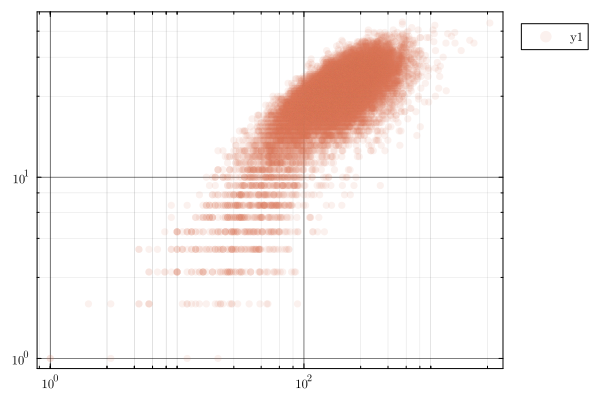

In [8]:
scatter(sum.([x[!,:N] for x in gd]), length.([x[!,:N] for x in gd]), xaxis = :log, yaxis = :log, alpha = 0.1)

In [9]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [10]:
df = DataFrame(y = logys, x = logxs);

In [11]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
─────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error       t  Pr(>|t|)  Lower 95%  Upper 95%
─────────────────────────────────────────────────────────────────────────
(Intercept)  0.243622  0.00669188   36.41    <1e-99   0.230506   0.256739
x            0.53443   0.00294296  181.60    <1e-99   0.528661   0.540198
─────────────────────────────────────────────────────────────────────────

In [12]:
coef(glm)

2-element Vector{Float64}:
 0.24362247886355665
 0.5344296790326689

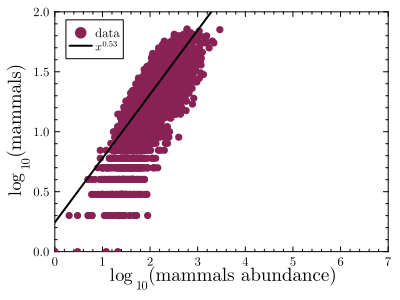

In [13]:
scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 1.0, label = "data", c = pal[8]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,7], ylims = [0,2], ylabel = L"$\log_{10}$(mammals)", xlabel = L"$\log_{10}$(mammals abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [14]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

In [19]:
cpal = [pal[i] for i in 0.0:1/length(gd):1];

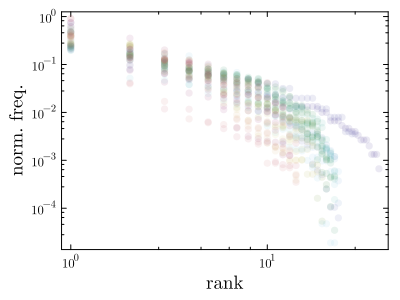

In [20]:
scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:length(gd)
    scatter!(sort(gd[si[i]][!,:N]./sum(gd[si[i]][!,:N]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)